# Analysing subcellular localisation with SubCellSpace

This notebook starts from `adata_subcell.h5ad` — the output of the processing pipeline, produced
in [`tutorial_creating_adata_subcell.ipynb`](./tutorial_creating_adata_subcell.ipynb). If you
have not made that file yet, start there.

The question we work towards is: **for each gene, is its distribution inside cells more
structured than chance, and if so, what kind of structure?**

The path to an answer has four parts:

1. **Reshape** the data so that one row is one (cell, gene) observation rather than one cell.
2. **Build a matched null** by shuffling molecules within each cell, then embedding those.
3. **Test each gene** against its own null, giving a patterned / not-patterned call.
4. **Explore** the latent space directly, without using labels at all.

The last two sections cover pattern subtypes and two interactive tools.

Throughout, the example data is the small-intestine MERFISH sample from the paper. It is
deliberately small (408 cells), so it runs in a couple of minutes on a laptop.

## Setup

Run this notebook from the repository root, in the analysis environment:

```bash
conda env create -f yamls/analysis_figures_crossplatform.yml
conda activate subcellspace_env
jupyter nbclassic          # nbclassic, if you want the interactive sections at the end
```

Note this is a *different* environment from the processing pipeline's `pyxel_env` — the analysis
code needs `POT` and `faiss`, which the processing environment does not carry.

In [1]:
# imports
import json
import pickle
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import awkward as ak
import matplotlib.pyplot as plt
import seaborn as sns
import torch

seed = 101
np.random.seed(seed)
torch.manual_seed(seed)

# SubCellSpace's analysis helpers; this notebook must be run from the repo root
sys.path.insert(0, "./make_paper_figures/src/")

# anndata flags its awkward-array support as experimental on every read; silence that one
# so it does not repeat through the notebook. FutureWarning is filtered defensively only.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Awkward Arrays.*")

%load_ext autoreload
%autoreload 2

## 1. Where the data comes from

Two paths to set: the pipeline output you want to analyse, and the trained model (needed to
embed the shuffled control later). Everything else is derived.

In [2]:
# >>> CHANGE THIS to your own pipeline output <<<
ADATA_PATH = Path("/mnt/data/david/subcellspace_data/small_intestine_data/adata_subcell.h5ad")

MODEL_PATH = Path("./SubCellSpace")                              # shipped in this repo
CLASSIFIER_BINARY = Path("./classifiers/rf_pattern_nonpattern.pkl")
CLASSIFIER_SUBTYPE = Path("./classifiers/multiclass_rf.pkl")

single_cell_adata = ad.read_h5ad(ADATA_PATH)
single_cell_adata

AnnData object with n_obs × n_vars = 408 × 547
    obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size'
    var: 'gene_name', 'gene_label'
    uns: 'detected_transcripts', 'measured_df'
    obsm: 'cell_mask', 'dapi_mask', 'detected_transcripts'
    layers: 'subcell_embedding'

One observation per **cell**, one variable per **gene**, and the subcellular information carried
alongside:

- `layers["subcell_embedding"]` — the 15-dimensional embedding, shape `(cells, genes, 15)`
- `obsm["dapi_mask"]`, `obsm["cell_mask"]` — the per-cell masks, flattened 100x100
- `obsm["detected_transcripts"]` — every molecule, with its position inside the cell

The gene panel usually includes control probes that are not real genes. Drop them up front —
you can read this from `var` directly, no need for the pipeline's `gene_map.json`.

In [3]:
gene_panel = [g for g in single_cell_adata.var["gene_name"]
              if not any(s in g for s in ("Unassigned", "NegControl", "Blank"))]
print(f"{len(gene_panel)} real genes out of {single_cell_adata.n_vars} panel entries")

499 real genes out of 547 panel entries


## 2. One row per observation, not per cell

Almost every question here is about a *(cell, gene) pair* — "is Apob localised in this cell?" —
not about a cell. So the first move is to flatten that three-dimensional layer into an ordinary
matrix where each row is one observation and the 15 columns are the latent dimensions.

`reshape_and_filter_anndata_with_index_and_mapping` does that and drops the pairs that were
never embedded (their embedding is a zero vector), keeping enough index columns to trace any row
back to the cell and gene it came from. **This is the single most important thing to understand
about working with these objects**: after the reshape, `obs["gene_name"]` is a property of the
row, and `X` is the embedding itself.

In [4]:
from adata_utils import (convertRecordToDf, decodeSubcellEmbedding,
                         getAllDetectedTranscripts, getXYOfSingleCell,
                         reshape_and_filter_anndata_with_index_and_mapping)
from plotting import plotFullDataPoint

adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata)
print(f"{single_cell_adata.n_obs} cells x {single_cell_adata.n_vars} genes"
      f"  ->  {adata.n_obs:,} observations x {adata.n_vars} latent dimensions")
adata.obs[["cell_id", "gene_name", "n_spots", "n_spots_interval"]].head()

408 cells x 547 genes  ->  3,358 observations x 15 latent dimensions


,cell_id,gene_name,n_spots,n_spots_interval
tile60_row6625_col2735_158_corrID_1_Ogdh,tile60_row6625_col2735_158_corrID_1,Ogdh,27.0,20-30
tile60_row6625_col2735_158_corrID_1_Vdr,tile60_row6625_col2735_158_corrID_1,Vdr,20.0,10-20
tile60_row6625_col2735_158_corrID_1_Pigr,tile60_row6625_col2735_158_corrID_1,Pigr,91.0,100+
tile60_row6625_col2735_158_corrID_1_Slc40a1,tile60_row6625_col2735_158_corrID_1,Slc40a1,47.0,40-50
tile60_row6625_col2735_158_corrID_1_Hnf4a,tile60_row6625_col2735_158_corrID_1,Hnf4a,14.0,10-20


Only pairs whose molecule count fell inside the pipeline's counting window carry an embedding, so
the number of observations is much smaller than `cells x genes`. How many observations each gene
has matters a great deal later: the statistical test compares *distributions*, so a gene seen in
a handful of cells cannot be called either way.

61 genes have at least one embedded observation
observations per gene: median 10, max 357
genes with >= 8 observations: 33


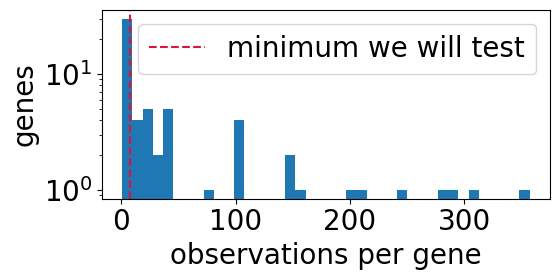

In [5]:
obs_per_gene = adata.obs["gene_name"].value_counts()
print(f"{len(obs_per_gene)} genes have at least one embedded observation")
print(f"observations per gene: median {obs_per_gene.median():.0f}, max {obs_per_gene.max()}")
print(f"genes with >= 8 observations: {(obs_per_gene >= 8).sum()}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(obs_per_gene.values, bins=40)
ax.axvline(8, color="crimson", ls="--", label="minimum we will test")
ax.set(xlabel="observations per gene", ylabel="genes", yscale="log")
ax.legend()
plt.tight_layout()

## 3. The matched null

To say a gene is "localised" we need something to compare against. The comparison used
throughout is the same gene, in the same cells, with the same number of molecules — but with
those molecules scattered uniformly at random inside the cell mask.

That is a deliberately conservative null. It holds constant everything about the cell that is
*not* the arrangement of molecules: its shape, its nucleus, how many molecules were detected. So
any difference between the real embeddings and the shuffled ones can only come from *where* the
molecules sit — not from cell size or detection efficiency.

**You probably already have this.** The processing pipeline computes it for you: with
`compute_random_control: true` (the default) it writes `layers["random_subcell_embedding"]`
alongside the real one. If your file came from the current pipeline, the cell below finds the
layer and does nothing.

The fallback exists for older files — like this example, which predates that feature — or if you
turned `compute_random_control` off. It performs the same operation the pipeline does: resample
each gene's molecule count uniformly from the cell-mask pixels, then embed the result with the
same model. One caveat if you use the fallback: it hardcodes the 10-100 molecule window, whereas
the pipeline exposes it as `spot_count_lower`/`spot_count_upper`. If you changed those, the
fallback will not match your data and you should re-run the pipeline instead.

In [6]:
from shuffle import shuffle_all_gene_expression, add_shuffled_embedding

# The column template for cells that have no molecules at all
transcript_columns = sorted(ak.to_list(single_cell_adata.obsm["detected_transcripts"][0]))

if "random_subcell_embedding" not in single_cell_adata.layers:
    single_cell_adata = shuffle_all_gene_expression(single_cell_adata, transcript_columns)
    model = torch.load(MODEL_PATH, map_location="cpu")
    single_cell_adata = add_shuffled_embedding(
        single_cell_adata, {"cvae": model["cvae"], "device": "cpu"})
    print("built random_subcell_embedding via the fallback (this file predates the pipeline "
          "feature)")
else:
    print("random_subcell_embedding already present -- the pipeline built it, nothing to do")

built random_subcell_embedding via the fallback (this file predates the pipeline feature)


In [7]:
random_adata = reshape_and_filter_anndata_with_index_and_mapping(
    single_cell_adata, layer="random_subcell_embedding")

# The test pairs each observation with its own shuffled twin, so the two must line up exactly
assert (adata.obs.index == random_adata.obs.index).all()
print(f"{adata.n_obs:,} real observations, each with a matched shuffled control")
print("mean |embedding| real vs shuffled:",
      f"{np.abs(adata.X).mean():.2f} vs {np.abs(random_adata.X).mean():.2f}")

3,358 real observations, each with a matched shuffled control
mean |embedding| real vs shuffled: 4.88 vs 4.56


Optionally save the object with its control layer, so you do not repeat the shuffle next time:

In [8]:
# single_cell_adata.write_h5ad(ADATA_PATH.with_name("adata_subcell_including_randomized.h5ad"),
#                              compression="gzip")

## 4. Is a gene patterned?

With a real embedding and a matched shuffled one for every observation, the test is:

1. A random forest, trained on simulated data, scores every embedding for how "patterned" it
   looks. This turns 15 dimensions into one number per observation.
2. For a given gene, compare the distribution of those scores against the distribution from its
   shuffled controls — the **earth-mover (Wasserstein) distance** for effect size, and a
   **Kolmogorov-Smirnov test** for significance.
3. Call a gene patterned only if it clears *both* a Bonferroni-corrected p-value and a minimum
   effect size.

Requiring both matters: with many observations a tiny difference becomes significant, and the
effect-size floor is what stops that being reported as biology.

In [9]:
from classifiers import classify_all_genes, classify_all_genes_for_pattern_subtypes

with open(CLASSIFIER_BINARY, "rb") as f:
    binary_classifier = pickle.load(f)
print("scores each observation as:", list(binary_classifier.classes_),
      f"| expects {binary_classifier.n_features_in_} features")

scores each observation as: ['pattern', 'random'] | expects 15 features


In [10]:
# Only test genes with enough observations to compare distributions at all
MIN_OBS = 8
testable = obs_per_gene[obs_per_gene >= MIN_OBS].index
adata_test = adata[adata.obs["gene_name"].isin(testable)].copy()
random_test = random_adata[adata_test.obs.index].copy()

print(f"testing {adata_test.obs['gene_name'].nunique()} genes "
      f"over {adata_test.n_obs:,} observations")

result_df = classify_all_genes(adata_test, binary_classifier, random_test, store_adata=False)
result_df.index = result_df["gene_name"]

testing 33 genes over 3,300 observations


`earth_dist` is the effect size, `bonferonni_pval` the corrected p-value, and `gene_pattern`
the combined call. The two thresholds are separate columns so you can see which one a gene
failed.

In [11]:
cols = ["gene_name", "n_obs", "earth_dist", "bonferonni_pval",
        "passes", "passes_earth_thresh", "gene_pattern"]
print(f"{int(result_df['gene_pattern'].sum())} of {len(result_df)} genes called patterned")
result_df.sort_values("earth_dist", ascending=False)[cols].head(12)

14 of 33 genes called patterned


,gene_name,n_obs,earth_dist,bonferonni_pval,passes,passes_earth_thresh,gene_pattern
gene_name,,,,,,,
Apob,Apob,357,0.502318,4.312703e-116,True,True,True
Clca1,Clca1,27,0.432810,1.072071e-08,True,True,True
Dync1h1,Dync1h1,15,0.426416,1.166038e-02,True,True,True
Clca4b,Clca4b,211,0.393977,3.567536e-44,True,True,True
Aoc1,Aoc1,284,0.386984,2.510021e-56,True,True,True
Gzma,Gzma,19,0.384112,1.378343e-04,True,True,True
Cdh1,Cdh1,8,0.315728,2.871795e+00,False,True,False
Ceacam1,Ceacam1,38,0.204401,1.199699e-03,True,True,True
Pigr,Pigr,307,0.199720,8.189277e-30,True,True,True


A note on thresholds, worth reading before trusting this on your own data. The default effect
size cut-off of 0.06 was calibrated on roughly a thousand observations per gene. In a dataset
this size the best-covered gene has a few hundred, so the cut-off is being applied off its
calibration point and is likely **conservative** — treat the number of hits as a floor. The
paper's power analysis shows how the detectable effect size varies with the number of cells; for
a small sample it is worth re-deriving the threshold rather than inheriting this one.

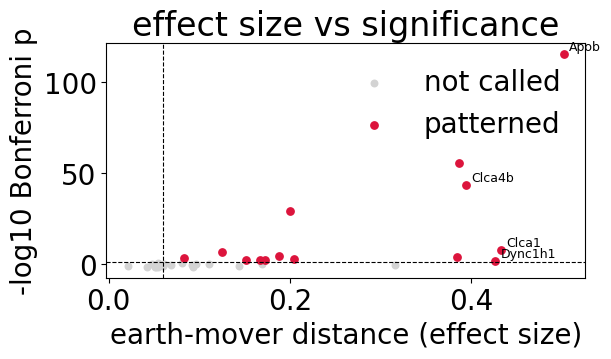

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4))
called = result_df["gene_pattern"]
ax.scatter(result_df.loc[~called, "earth_dist"],
           -np.log10(result_df.loc[~called, "bonferonni_pval"].clip(lower=1e-300)),
           s=22, c="lightgrey", label="not called")
ax.scatter(result_df.loc[called, "earth_dist"],
           -np.log10(result_df.loc[called, "bonferonni_pval"].clip(lower=1e-300)),
           s=28, c="crimson", label="patterned")
for g in result_df.nlargest(4, "earth_dist")["gene_name"]:
    r = result_df.loc[g]
    ax.annotate(g, (r["earth_dist"], -np.log10(max(r["bonferonni_pval"], 1e-300))),
                fontsize=9, xytext=(4, 3), textcoords="offset points")
ax.axvline(0.06, ls="--", c="k", lw=0.8)
ax.axhline(-np.log10(0.05), ls="--", c="k", lw=0.8)
ax.set(xlabel="earth-mover distance (effect size)",
       ylabel="-log10 Bonferroni p", title="effect size vs significance")
ax.legend(frameon=False)
plt.tight_layout()

The dashed lines are the two thresholds; a gene must be right of one and above the other. The
genes in the top-right are the ones worth looking at by eye — which is the next cell.

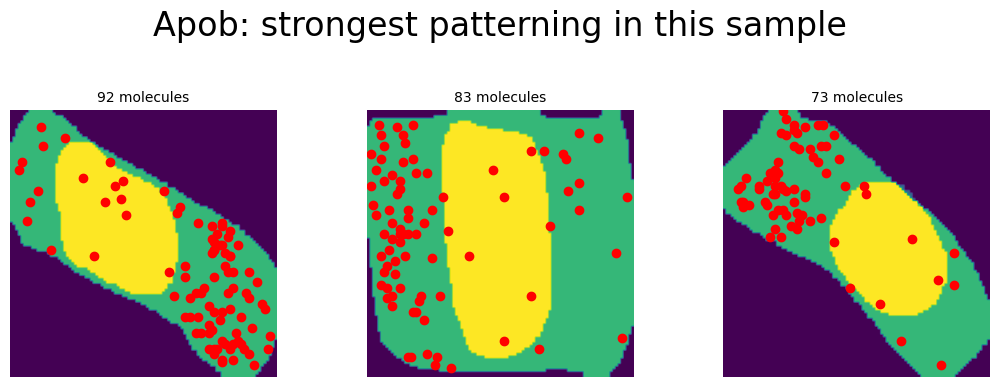

In [13]:
# Look at the strongest hit directly: the molecules of that gene, in one cell
top_gene = result_df.sort_values("earth_dist", ascending=False)["gene_name"].iloc[0]
rows = adata.obs[adata.obs["gene_name"] == top_gene].nlargest(3, "n_spots")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, (_, row) in zip(axes, rows.iterrows()):
    plotFullDataPoint(single_cell_adata, tile_nr=int(row["tile_nr"]),
                      cell_id=row["cell_id"], gene=top_gene, ax=ax)
    ax.set_title(f"{int(row['n_spots'])} molecules", fontsize=10)
    ax.axis("off")
fig.suptitle(f"{top_gene}: strongest patterning in this sample", y=1.02)
plt.tight_layout()

## 5. Which pattern?

A second, multi-class random forest assigns a *kind* of localisation. It is applied only to the
genes that passed the binary test — running it on everything produces a misleading answer,
because on an unpatterned gene the classifier still has to output something and its prior
dominates.

`classify_all_genes_for_pattern_subtypes` needs the per-gene observations, so we re-run the
binary step with `store_adata=True` to keep them attached.

In [14]:
with open(CLASSIFIER_SUBTYPE, "rb") as f:
    subtype_classifier = pickle.load(f)
print("subtypes:", list(subtype_classifier.classes_))

result_df = classify_all_genes(adata_test, binary_classifier, random_test, store_adata=True)
result_df.index = result_df["gene_name"]
result_df = classify_all_genes_for_pattern_subtypes(result_df, subtype_classifier)

patterned = result_df[result_df["final_class"] != "random"]
print(f"\n{len(patterned)} patterned genes, by subtype:")
print(patterned["final_class"].value_counts().to_string())

subtypes: ['cell-edge', 'extranuclear', 'intranuclear', 'pericellular', 'perinuclear', 'protrusion', 'random']



14 patterned genes, by subtype:
pericellular    11
extranuclear     2
cell-edge        1


In [15]:
patterned.sort_values("earth_dist", ascending=False)[
    ["gene_name", "n_obs", "earth_dist", "bonferonni_pval", "final_class"]].head(12)

,gene_name,n_obs,earth_dist,bonferonni_pval,final_class
gene_name,,,,,
Apob,Apob,357,0.502318,4.312703e-116,pericellular
Clca1,Clca1,27,0.432810,1.072071e-08,pericellular
Dync1h1,Dync1h1,15,0.426416,1.166038e-02,pericellular
Clca4b,Clca4b,211,0.393977,3.567536e-44,pericellular
Aoc1,Aoc1,284,0.386984,2.510021e-56,pericellular
Gzma,Gzma,19,0.384112,1.378343e-04,pericellular
Ceacam1,Ceacam1,38,0.204401,1.199699e-03,extranuclear
Pigr,Pigr,307,0.199720,8.189277e-30,pericellular
Slc40a1,Slc40a1,81,0.187589,2.931987e-05,pericellular


`subtype_pattern` holds the raw argmax for every gene, patterned or not; `final_class` is that
value only where the gene passed, and `"random"` otherwise. Use `final_class`. The raw column on
unpatterned genes reflects the classifier's prior, not biology.

## 6. Exploring the latent space without labels

Everything so far leaned on classifiers trained on simulations. It is worth also looking at the
space directly: cluster the observations on their embeddings, then ask what each cluster looks
like. That can surface patterns the classifiers were never trained to name.

In [16]:
import igraph  # noqa: F401  (used via scanpy's graph conversion below)

sc.pp.neighbors(adata, n_neighbors=25, use_rep="X")
sc.tl.umap(adata)

# scanpy's own leiden is fine, but going through igraph directly is much faster on large objects
adjacency = sc._utils._choose_graph(adata, obsp=None, neighbors_key="neighbors")
graph = sc._utils.get_igraph_from_adjacency(adjacency)
resolution = 0.6
clustering = graph.community_leiden(objective_function="modularity",
                                    resolution=resolution, n_iterations=-1)
adata.obs["leiden"] = pd.Categorical([str(c) for c in clustering.membership])
print(f"{adata.obs['leiden'].nunique()} clusters; sizes:")
print(adata.obs["leiden"].value_counts().to_string())

7 clusters; sizes:
0    832
1    559
4    479
2    408
5    387
6    360
3    333


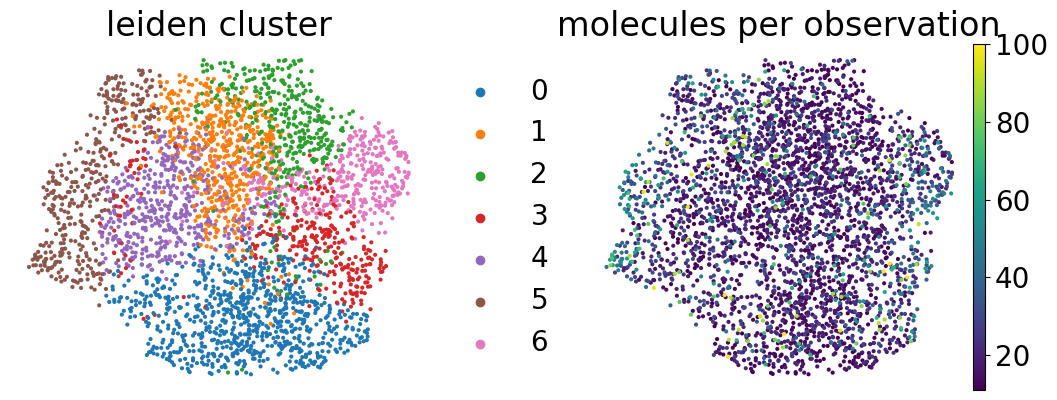

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sc.pl.umap(adata, color="leiden", ax=axes[0], show=False, frameon=False, title="leiden cluster")
sc.pl.umap(adata, color="n_spots", ax=axes[1], show=False, frameon=False,
           title="molecules per observation", cmap="viridis")
plt.tight_layout()

### What does a cluster mean?

The model is an autoencoder, so a point in the latent space can be turned back into an image.
Averaging the embeddings of a cluster and decoding that average gives a picture of what the
cluster represents — the most direct answer available to "what did the model learn?".

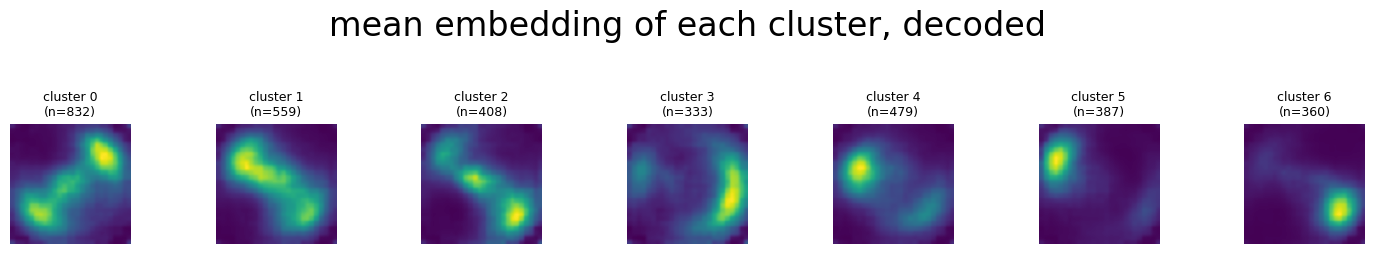

In [18]:
from skimage.filters import gaussian

model = torch.load(MODEL_PATH, map_location="cpu")
decode_model = {"cvae": model["cvae"], "device": "cpu"}

clusters = sorted(adata.obs["leiden"].unique(), key=int)
fig, axes = plt.subplots(1, len(clusters), figsize=(2.1 * len(clusters), 2.5))
for ax, cl in zip(np.atleast_1d(axes), clusters):
    mean_embedding = adata[adata.obs["leiden"] == cl].X.mean(axis=0)[None, :]
    ax.imshow(gaussian(decodeSubcellEmbedding(mean_embedding, decode_model), 1.0))
    ax.set_title(f"cluster {cl}\n(n={(adata.obs['leiden'] == cl).sum()})", fontsize=9)
    ax.axis("off")
fig.suptitle("mean embedding of each cluster, decoded", y=1.06)
plt.tight_layout()

### Is a cluster enriched for anything you know?

If your cells carry annotations — cell type, condition, region — this is where you would test
whether a localisation cluster tracks them. This example dataset has no biological annotation, so
we use molecule count as a stand-in purely to show the mechanics: **substitute your own column
here.**

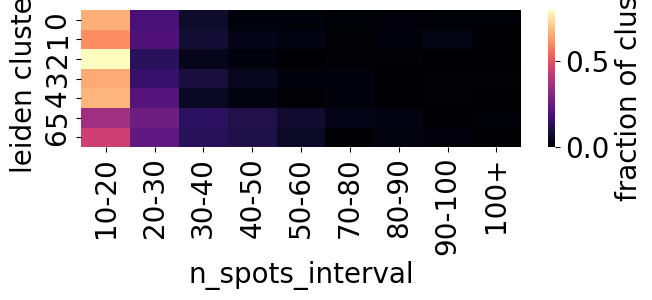

In [19]:
meta_variable = "n_spots_interval"      # <- replace with your cell type / condition / region

crosstab = pd.crosstab(adata.obs["leiden"], adata.obs[meta_variable], normalize="index")
crosstab = crosstab.loc[:, crosstab.sum() > 0]

fig, ax = plt.subplots(figsize=(7, 3.4))
sns.heatmap(crosstab, cmap="magma", ax=ax, cbar_kws={"label": "fraction of cluster"})
ax.set(xlabel=meta_variable, ylabel="leiden cluster")
plt.tight_layout()

## 7. Gene pairs that co-localise

The same embeddings let you ask whether two genes occupy the same place *within the same cell* —
useful for spotting genes that traffic together, or that segregate. For each cell where both
genes are present, take the distance between their embeddings; genes that repeatedly land close
together are candidates.

In [20]:
import ot   # POT: optimal transport, used here just for a pairwise distance matrix

def latent_distance(gene_a, gene_b, min_shared_cells=4):
    a = adata[adata.obs["gene_name"] == gene_a]
    b = adata[adata.obs["gene_name"] == gene_b]
    shared = np.intersect1d(a.obs["cell_id"], b.obs["cell_id"])
    if len(shared) < min_shared_cells:
        return None, len(shared)
    da = a[a.obs["cell_id"].isin(shared)]
    db = b[b.obs["cell_id"].isin(shared)]
    # mean distance between the two genes' embeddings, cell by cell
    order_a = np.argsort(da.obs["cell_id"].values)
    order_b = np.argsort(db.obs["cell_id"].values)
    n = min(len(order_a), len(order_b))
    d = np.linalg.norm(da.X[order_a][:n] - db.X[order_b][:n], axis=1)
    return float(d.mean()), n

# Restrict to the well-covered genes; all pairs would be O(n^2) and mostly empty
busy = obs_per_gene[obs_per_gene >= 100].index.tolist()
print(f"comparing {len(busy)} well-covered genes ({len(busy) * (len(busy) - 1) // 2} pairs)")

pairs = []
for i, ga in enumerate(busy):
    for gb in busy[i + 1:]:
        dist, n = latent_distance(ga, gb)
        if dist is not None:
            pairs.append({"gene_a": ga, "gene_b": gb, "mean_distance": dist, "n_cells": n})

pair_df = pd.DataFrame(pairs).sort_values("mean_distance")
print(f"{len(pair_df)} pairs shared enough cells to compare")
pair_df.head(8)

comparing 13 well-covered genes (78 pairs)


78 pairs shared enough cells to compare


,gene_a,gene_b,mean_distance,n_cells
34,Aoc1,Clca4b,7.405809,187
2,Apob,Aoc1,7.947713,274
43,Ogdh,Pkm,7.953879,173
72,Vdr,Eif4h,7.978004,60
24,Cyb5r3,Ogdh,8.088339,227
71,Epcam,Dpp4,8.178584,76
70,Epcam,Erbb3,8.207594,75
73,Vdr,Erbb3,8.229486,61


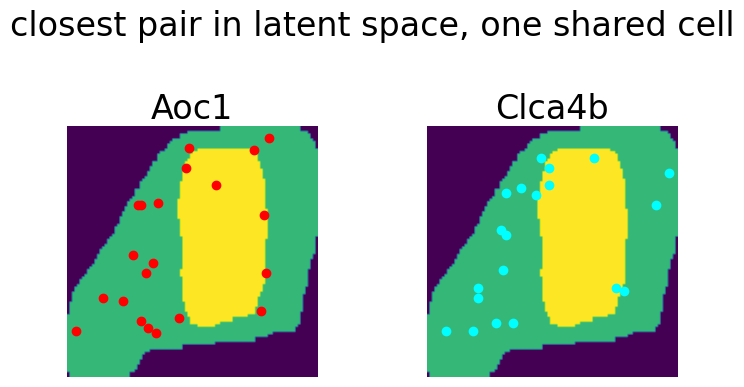

In [21]:
# The closest pair, side by side in one cell
if len(pair_df):
    ga, gb = pair_df.iloc[0][["gene_a", "gene_b"]]
    cells_a = set(adata.obs.loc[adata.obs["gene_name"] == ga, "cell_id"])
    cells_b = set(adata.obs.loc[adata.obs["gene_name"] == gb, "cell_id"])
    shared = sorted(cells_a & cells_b)
    if shared:
        cell = shared[0]
        tile = int(adata.obs.loc[adata.obs["cell_id"] == cell, "tile_nr"].iloc[0])
        fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.9))
        for ax, g, colour in zip(axes, (ga, gb), ("red", "cyan")):
            plotFullDataPoint(single_cell_adata, tile_nr=tile, cell_id=cell,
                              gene=g, ax=ax, color=colour)
            ax.set_title(g)
            ax.axis("off")
        fig.suptitle(f"closest pair in latent space, one shared cell", y=1.02)
        plt.tight_layout()

## 8. Interactive tools

Two exploratory tools ship with the repository. They need mouse input, so they cannot be run
non-interactively and the cells below are left unexecuted on purpose. To use them, open this
notebook in **`jupyter nbclassic`** — the classic interface, which the figure notebooks also
recommend, because the modern JupyterLab interactive backends have been unreliable for this.

The first lets you click anywhere in the latent-space plot and see the observation nearest to
where you clicked, which is a fast way to get a feel for what a region of the space contains.

In [22]:
# Requires: jupyter nbclassic, and %matplotlib notebook
# %matplotlib notebook
#
# from scipy import spatial
#
# def click_to_inspect(adata, basis="X_umap"):
#     coords = adata.obsm[basis]
#     tree = spatial.KDTree(coords)
#     fig, (ax_space, ax_cell) = plt.subplots(1, 2, figsize=(11, 5))
#     ax_space.scatter(coords[:, 0], coords[:, 1], s=4, c="lightgrey")
#
#     def onclick(event):
#         if event.inaxes is not ax_space:
#             return
#         _, idx = tree.query([event.xdata, event.ydata])
#         row = adata.obs.iloc[idx]
#         ax_cell.clear()
#         plotFullDataPoint(single_cell_adata, tile_nr=int(row["tile_nr"]),
#                           cell_id=row["cell_id"], gene=row["gene_name"], ax=ax_cell)
#         ax_cell.set_title(f"{row['gene_name']} in {row['cell_id']}")
#         ax_cell.axis("off")
#         fig.canvas.draw_idle()
#
#     fig.canvas.mpl_connect("button_press_event", onclick)
#     return fig
#
# click_to_inspect(adata)

The second goes the other way: draw a pattern by hand, embed the drawing, and find the real
observations closest to it. That is a direct way to ask "does anything in my data look like
*this*?".

In [23]:
# Requires: jupyter nbclassic, and %matplotlib notebook
# %matplotlib notebook
#
# from skimage.filters import gaussian
# from skimage.transform import rotate
# from subcellspace_utils import prepare_new_input        # or CVAE's prepare_new_input
#
# def draw_and_match(adata, single_cell_adata, model, n_matches=4):
#     canvas = np.zeros((100, 100))
#     fig, ax = plt.subplots(figsize=(5, 5))
#     ax.imshow(canvas, cmap="gray")
#
#     def on_move(event):
#         if event.button == 1 and event.inaxes is ax:
#             canvas[int(event.ydata), int(event.xdata)] = 1.0
#             ax.imshow(gaussian(canvas, 1.5), cmap="gray")
#             fig.canvas.draw_idle()
#
#     fig.canvas.mpl_connect("motion_notify_event", on_move)
#     # When finished drawing, embed the canvas and compare against every observation:
#     #   query = model["cvae"].embed(prepare_new_input(gaussian(canvas, 1.5)))[0]
#     #   distances = np.linalg.norm(adata.X - query.detach().numpy(), axis=1)
#     #   best = adata.obs.iloc[np.argsort(distances)[:n_matches]]
#     # then plot those with plotFullDataPoint, optionally rotating the drawing to match.
#     return fig
#
# draw_and_match(adata, single_cell_adata, torch.load(MODEL_PATH, map_location="cpu"))

## Where to go next

- **Reproduce the paper's figures** — [`make_paper_figures/`](./make_paper_figures/), which uses
  the same helpers on the full datasets from the Zenodo record.
- **Process another sample** — back to
  [`tutorial_creating_adata_subcell.ipynb`](./tutorial_creating_adata_subcell.ipynb).
- **Re-derive the thresholds for your sample size** — see the power analysis in
  `make_paper_figures/src/power_analysis.py` and the corresponding figure. Worth doing before
  reporting hit counts from a dataset much smaller or larger than the ones used here.